# 02 · Features derivadas y prueba de no fuga

**Cómo se usa el modelo.** En una fecha de corte *c* se conoce la historia hasta *c* y se pide
el pronóstico de cada día *t = c+1, …, c+16*. El modelo es **directo**: un único modelo que
predice cualquier día del horizonte. Por eso toda feature calculada a partir de ventas o
transacciones usa solo datos de **t−16 o antes**: así existe incluso para el día más lejano
(*t = c+16* → *t−16 = c*). Del propio día *t* solo entra lo que se planifica de antemano:
calendario, feriados y eventos.

```
historia conocida ──────────────┤ c ├── horizonte (16 días) ──┤
                       t−16 ────┘        t = c+16  (peor caso)
```

Este notebook:

1. Define cada feature con la evidencia del EDA que la justifica (§1–§3).
2. Explica la codificación de las categóricas (§4).
3. **Demuestra** que no hay fuga, alterando el futuro y comprobando que las features no cambian (§5).
4. Decide, con una ablación, si `ONPROMOTION` entra al modelo (§6).

El código vive en `src/pipeline.py` (`construir_features`, `dividir`, `preparacion`). Los notebooks siguientes lo importan.
**El conjunto de prueba (31/07–15/08/2017) no se usa aquí.** La ablación se valida en los 16 días
anteriores (15/07–30/07).

In [1]:
import sys
import time
import warnings

sys.path.insert(0, '..')
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline

from src.datos import cargar_muestra
from src.pipeline import (CATEGORICAS, CLAVE, DERIVADAS, EXCLUIDAS, HORIZONTE, INICIO_MODELADO,
                          INICIO_PRUEBA, NUMERICAS, OBJETIVO, PROMOCION, YA_LISTAS,
                          construir_features, dividir, preparacion, rmsle)

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

FIGURAS = '../docs/figuras'
AZUL, NARANJA, GRIS = '#2a78d6', '#eb6834', '#f0efec'
TINTA, TINTA_2 = '#0b0b0b', '#52514e'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#b8b7b0',
    'axes.labelcolor': TINTA_2, 'xtick.color': TINTA_2, 'ytick.color': TINTA_2,
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
})


def comprobar(numero, condicion):
    if condicion:
        print(f"Comprobación {numero}: OK")
    else:
        print(f"Comprobación {numero}: revisa")


ventas, meta = cargar_muestra()
print('Huella de la muestra:', meta['sha256'])

Huella de la muestra: 4c43165b8f2b72904e5163ee431b3d9dee18bec1c820ee2a4deb035538e899cc


## 1. Catálogo de features

Las ventas entran en escala `log1p`, la misma del objetivo con el que se entrena (hallazgo 1 del
EDA). Ventana `[a, b]` = días de calendario de *t−a* a *t−b*, ambos incluidos.

| Feature | Definición | Evidencia (EDA) | ¿Existe al predecir? |
|---|---|---|---|
| `venta_lag_16` | venta de *t−16* | Spearman 0,63 (§5.2) | Sí: *t−16 ≤ c* |
| `venta_lag_21/28/35/42` | venta del mismo día de la semana, 3–6 semanas antes | Rezago 21 ≈ 0,66 > rezago 16; ciclo semanal (§5.2) | Sí |
| `media_mismo_dia_4` | media de los cuatro rezagos anteriores | Promediar reduce el ruido de un solo día | Sí |
| `media_7_desde_16` | media de `[22, 16]` | Nivel reciente | Sí |
| `media_28_desde_16` | media de `[43, 16]` | Mejor correlación del EDA, ≈ 0,75 | Sí |
| `std_28_desde_16` | desviación de `[43, 16]` | Volatilidad de la serie, útil también para el stock de seguridad | Sí |
| `frac_ceros_28_desde_16` | fracción de días sin venta en `[43, 16]` | Hallazgo 3: de 6 % a 89 % de ceros según la intermitencia (§6) | Sí |
| `dias_sin_venta_16` | días desde la última venta, vistos en *t−16* (tope 90) | Series que dejan de venderse (PREPARED FOODS, §3) | Sí |
| `nivel_serie_16` | media histórica de la serie hasta *t−16* | Hallazgo 4: escalas de 0,7 a 67 unidades diarias (§5.4) | Sí |
| `transacciones_lag_16` | `log1p` de transacciones de la tienda en *t−16* | Hallazgo 5: las del mismo día no existen al predecir | Sí |
| `DAY_OF_WEEK_ISO` | día de la semana (categórica) | Ciclo semanal (§5.2) | Sí: calendario |
| `DAY_OF_MONTH`, `IS_PAYDAY_PROXY`, `IS_MONTH_END` | día del mes y quincenas | Pago de salarios públicos los días 15 y fin de mes | Sí: calendario |
| `IS_HOLIDAY`, `IS_TRANSFER_DAY`, `IS_ADDITIONAL_DAY`, `IS_BRIDGE_DAY`, `IS_WORK_DAY`, `HAS_SPECIAL_EVENT`, `APPLICABLE_EVENT_COUNT` | feriados y eventos aplicables a la tienda | Calendario oficial, publicado con antelación | Sí |
| `FAMILY`, `ITEM_CLASS`, `STORE_TYPE`, `STORE_CLUSTER` | atributos del producto y de la tienda | Estáticos | Sí |

**Por qué rezagos de calendario y no de fila.** La serie puede tener días sin fila (25/12 cerrado y
algunos huecos de tienda). `construir_features` pasa la muestra a una matriz serie × fecha con
**todas** las fechas, así *t−16* es siempre 16 días de calendario y no "16 filas atrás".

Las columnas que **no** entran y su motivo están en `EXCLUIDAS`:

In [2]:
pd.DataFrame({'motivo': EXCLUIDAS}).rename_axis('columna excluida')

,motivo
columna excluida,
UNIT_SALES_ORIGINAL,es el objetivo sin recortar
IS_RETURN,se deriva del objetivo del mismo día
IS_OBSERVED,auditoría del PSet 2: revela si hubo venta
IS_IMPUTED_ZERO,auditoría del PSet 2: revela y = 0
IS_ONPROMOTION_IMPUTED,auditoría del PSet 2: revela y = 0
IS_AFTER_LAST_SALE,auditoría del PSet 2: usa el futuro de la serie
TRANSACTIONS_OBSERVED,mismo día: no existe al predecir (se usa rezag...
IS_TRANSACTIONS_MISSING,mismo día: no existe al predecir
OIL_PRICE_PREPARED,mismo día y sin relación con el objetivo (EDA §5)


## 2. Construcción

`construir_features` devuelve una fila por tienda–producto–día desde el 13/09/2016, el primer día
con la ventana `[43, 16]` completa. Lo anterior solo sirve de historia. Los faltantes que
quedan corresponden a series que empiezan más tarde: no hay rezagos antes de su primera venta.

In [3]:
inicio = time.perf_counter()
datos = construir_features(ventas)
segundos = time.perf_counter() - inicio

print(f'{len(datos):,} filas, {datos["DATE"].min():%Y-%m-%d} a {datos["DATE"].max():%Y-%m-%d}, '
      f'{segundos:.1f} s')
print(f'Features: {len(NUMERICAS)} numéricas, {len(YA_LISTAS)} ya listas (0/1), '
      f'{len(CATEGORICAS)} categóricas')
datos[DERIVADAS].describe().T.assign(faltantes=datos[DERIVADAS].isna().mean())

625,174 filas, 2016-09-13 a 2017-08-15, 1.2 s
Features: 15 numéricas, 8 ya listas (0/1), 5 categóricas


,count,mean,std,min,25%,50%,75%,max,faltantes
venta_lag_16,"614,927.0000",1.4383,1.1646,0.0000,0.0000,1.3863,2.1997,7.2549,0.0164
venta_lag_21,"612,804.0000",1.4388,1.1633,0.0000,0.2255,1.3863,2.1972,7.2549,0.0198
venta_lag_28,"609,742.0000",1.4432,1.1624,0.0000,0.3627,1.3863,2.2075,7.2549,0.0247
venta_lag_35,"606,562.0000",1.4470,1.1613,0.0000,0.4455,1.3863,2.2158,7.2549,0.0298
venta_lag_42,"603,025.0000",1.4517,1.1597,0.0000,0.5283,1.3863,2.2270,7.2549,0.0354
media_mismo_dia_4,"616,521.0000",1.4431,1.0342,0.0000,0.6598,1.3144,2.0928,6.1048,0.0138
media_7_desde_16,"617,814.0000",1.4393,1.0130,0.0000,0.6931,1.3213,2.0702,5.6557,0.0118
media_28_desde_16,"613,016.0000",1.4450,0.9762,0.0000,0.7356,1.3131,2.0388,5.4812,0.0194
std_28_desde_16,"613,016.0000",0.5857,0.2664,0.0000,0.4603,0.5800,0.7145,2.4505,0.0194
frac_ceros_28_desde_16,"613,016.0000",0.2464,0.3018,0.0000,0.0000,0.1111,0.3571,1.0000,0.0194


## 3. Evidencia: cada feature contra el objetivo

Spearman con `log1p(y)`, **solo con filas anteriores a la prueba**, para no mirar el conjunto que
decide al final. Se usa Spearman porque el EDA mostró que Pearson se infla con las series grandes
(§5.1).

In [4]:
previo = datos[datos['DATE'] < INICIO_PRUEBA]
log_y = np.log1p(previo[OBJETIVO])
evidencia = (previo[NUMERICAS + YA_LISTAS].corrwith(log_y, method='spearman')
             .rename('spearman').to_frame()
             .assign(faltantes=previo[NUMERICAS + YA_LISTAS].isna().mean())
             .sort_values('spearman', key=abs, ascending=False))
evidencia

,spearman,faltantes
media_28_desde_16,0.7550,0.0205
media_7_desde_16,0.7390,0.0124
media_mismo_dia_4,0.7368,0.0146
nivel_serie_16,0.7356,0.0128
venta_lag_21,0.6599,0.0209
frac_ceros_28_desde_16,-0.6570,0.0205
venta_lag_28,0.6545,0.0260
venta_lag_35,0.6432,0.0314
venta_lag_42,0.6371,0.0373
venta_lag_16,0.6339,0.0173


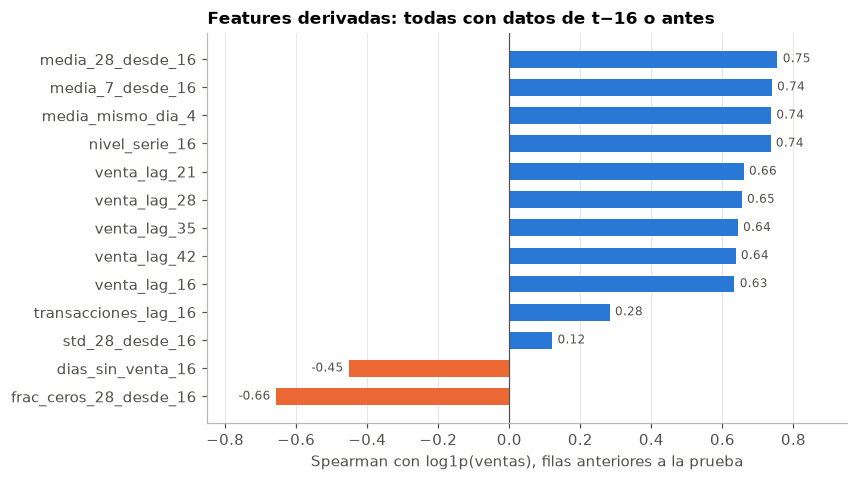

In [5]:
orden = evidencia.loc[DERIVADAS].sort_values('spearman')
fig, ax = plt.subplots(figsize=(7.5, 4.6))
colores = [AZUL if v >= 0 else NARANJA for v in orden['spearman']]
ax.barh(orden.index, orden['spearman'], color=colores, height=0.6)
for i, v in enumerate(orden['spearman']):
    ax.text(v + (0.015 if v >= 0 else -0.015), i, f'{v:.2f}', va='center',
            ha='left' if v >= 0 else 'right', fontsize=8, color=TINTA_2)
ax.axvline(0, color=TINTA_2, linewidth=0.8)
ax.set_xlim(-0.85, 0.95)
ax.set_xlabel('Spearman con log1p(ventas), filas anteriores a la prueba')
ax.set_title('Features derivadas: todas con datos de t−16 o antes')
ax.grid(axis='y', visible=False)
fig.savefig(f'{FIGURAS}/features_spearman.png')
plt.show()

**Lectura.**

- Las medias desplazadas (`media_28_desde_16`, `media_mismo_dia_4`, `nivel_serie_16`) superan a
  cualquier rezago individual, porque promediar quita el ruido diario.
- La intermitencia (`frac_ceros_28_desde_16`, `dias_sin_venta_16`) es la señal negativa más fuerte:
  dice cuándo predecir cerca de cero.
- Las variables de calendario tienen correlación marginal baja, pero **modulan** el nivel (día de la
  semana, quincena). Los modelos de árboles y la red las combinan con el nivel; Ridge lo hace con
  efectos aditivos en escala log.
- Hay redundancia entre rezagos (el EDA midió 0,64–0,81 entre ellos). Ridge la tolera gracias a
  la penalización, y los árboles eligen una de las variables redundantes en cada división.

## 4. Codificación de las categóricas

`preparacion()` es un `ColumnTransformer` con los bloques `numericas`,
`ya_listas` y `categoricas`, con dos ajustes:

- **Numéricas: mediana + indicador de faltante** (`add_indicator=True`). Un rezago vacío no
  significa "venta típica": significa "serie nueva". El indicador le permite al modelo distinguirlo.
- **Categóricas: one-hot con agrupación de infrecuentes** (`min_frequency=0.001`,
  `handle_unknown='infrequent_if_exist'`). `ITEM_CLASS` tiene decenas de clases y varias aparecen en
  pocas series; agruparlas evita columnas que solo memorizan un producto.

¿Por qué one-hot y no otra codificación?

- **Ordinal** impondría un orden falso entre clases o tipos de tienda, que Ridge y la red tomarían
  como magnitud.
- **Target encoding** usa el objetivo y obliga a calcularlo dentro de cada pliegue para no filtrar
  información. Aporta poco aquí, porque `nivel_serie_16` ya resume el nivel de cada serie.
- **One-hot de `STORE_NBR` o `ITEM_NBR`** (54 tiendas, cientos de productos) memorizaría
  identidades. Se excluyen.

Todo el `ColumnTransformer` se ajusta **dentro** del `Pipeline` y solo con el entrenamiento de cada
pliegue: medianas, medias, desviaciones y categorías salen de ahí (notebook 03).

In [6]:
X_ent, X_val, y_ent, y_val = dividir(datos, inicio_prueba='2017-07-15')
preparar = preparacion().fit(X_ent)
nombres = preparar.get_feature_names_out()

cardinalidad = pd.DataFrame({
    'categorias': X_ent[CATEGORICAS].nunique(),
    'columnas_one_hot': [sum(n.startswith(f'categoricas__{c}_') for n in nombres) for c in CATEGORICAS],
})
print(f'Matriz preparada: {len(X_ent):,} filas × {len(nombres)} columnas')
cardinalidad

Matriz preparada: 561,174 filas × 156 columnas


,categorias,columnas_one_hot
DAY_OF_WEEK_ISO,7,7
FAMILY,9,9
ITEM_CLASS,88,82
STORE_TYPE,5,5
STORE_CLUSTER,17,17


## 5. Prueba de no fuga

Que el código "parezca" correcto no basta; se comprueba de tres formas.

### 5.1 Recalcular a mano

Para 2.000 filas al azar, `venta_lag_16` debe ser `log1p` de la venta de esa misma serie 16 días
de calendario antes (o faltar si ese día no existe), y `media_28_desde_16` la media de los días
`[t−43, t−16]`.

In [7]:
muestra = datos.sample(2000, random_state=42)[CLAVE + ['venta_lag_16', 'media_28_desde_16']]
hace_16 = ventas[CLAVE + [OBJETIVO]].assign(DATE=lambda d: d['DATE'] + pd.Timedelta(days=16))
cruce = muestra.merge(hace_16, on=CLAVE, how='left')
iguales_lag = np.allclose(cruce['venta_lag_16'], np.log1p(cruce[OBJETIVO]), equal_nan=True)

por_serie = ventas.set_index(CLAVE)[OBJETIVO].sort_index()
errores = []
for _, fila in muestra.head(300).iterrows():
    historia = por_serie.loc[(fila['STORE_NBR'], fila['ITEM_NBR'])]
    ventana = historia.loc[fila['DATE'] - pd.Timedelta(days=43): fila['DATE'] - pd.Timedelta(days=16)]
    if len(ventana) >= 14:
        errores.append(abs(np.log1p(ventana).mean() - fila['media_28_desde_16']))

print(f'venta_lag_16 = log1p(y[t−16]) en las 2.000 filas: {iguales_lag}')
print(f'media_28_desde_16: error máximo {max(errores):.2e} en {len(errores)} filas')
comprobar(1, iguales_lag and max(errores) < 1e-9)

venta_lag_16 = log1p(y[t−16]) en las 2.000 filas: True
media_28_desde_16: error máximo 1.33e-15 en 295 filas
Comprobación 1: OK


### 5.2 Alterar el futuro

La prueba más directa: tomar un corte *c* y **destruir** todo lo posterior. Las ventas se permutan
al azar y se transforman, y las transacciones se multiplican por 5. Luego se recalculan las
features. Si alguna usara información posterior a *c*, cambiaría en algún día ≤ *c+16*.

- **Corte 30/07/2017**, el día antes de la prueba. Prueba que las features del conjunto de prueba
  completo (31/07–15/08) **no dependen de sus propias ventas**.
- **Corte 30/06/2017**, como **control positivo**. A partir de *c+17* las features **sí** deben
  cambiar. Si no cambiaran, la prueba no estaría midiendo nada.

In [8]:
def features_alteradas(corte, semilla=42):
    # Recalcula las features con todo lo posterior al corte destruido y cuenta,
    # por fecha, cuántas features derivadas cambiaron en alguna serie.
    alterado = ventas.copy()
    futuro = alterado['DATE'] > corte
    rng = np.random.default_rng(semilla)
    alterado.loc[futuro, OBJETIVO] = rng.permutation(alterado.loc[futuro, OBJETIVO].to_numpy()) * 3 + 1
    alterado.loc[futuro, 'TRANSACTIONS_OBSERVED'] *= 5
    a = datos.set_index(CLAVE)[DERIVADAS]
    b = construir_features(alterado).set_index(CLAVE)[DERIVADAS]
    cambio = ~(np.isclose(a, b, equal_nan=True))
    return pd.DataFrame(cambio, index=a.index, columns=DERIVADAS).groupby(level='DATE').any().sum(axis=1)


pruebas = {}
for corte in ['2017-07-30', '2017-06-30']:
    c = pd.Timestamp(corte)
    cambiadas = features_alteradas(c)
    pruebas[corte] = cambiadas
    hasta = cambiadas.loc[:c + pd.Timedelta(days=HORIZONTE)]
    despues = cambiadas.loc[c + pd.Timedelta(days=HORIZONTE + 1):]
    print(f'corte {corte}: features alteradas hasta c+16 = {hasta.max()}; '
          f'desde c+17 = {despues.max() if len(despues) else "sin fechas (fin de la OBT)"}')

c1, c2 = pd.Timestamp('2017-07-30'), pd.Timestamp('2017-06-30')
comprobar(2, pruebas['2017-07-30'].max() == 0)
comprobar(3, pruebas['2017-06-30'].loc[:c2 + pd.Timedelta(days=16)].max() == 0
          and pruebas['2017-06-30'].loc[c2 + pd.Timedelta(days=17)] > 0)

corte 2017-07-30: features alteradas hasta c+16 = 0; desde c+17 = sin fechas (fin de la OBT)


corte 2017-06-30: features alteradas hasta c+16 = 0; desde c+17 = 13
Comprobación 2: OK
Comprobación 3: OK


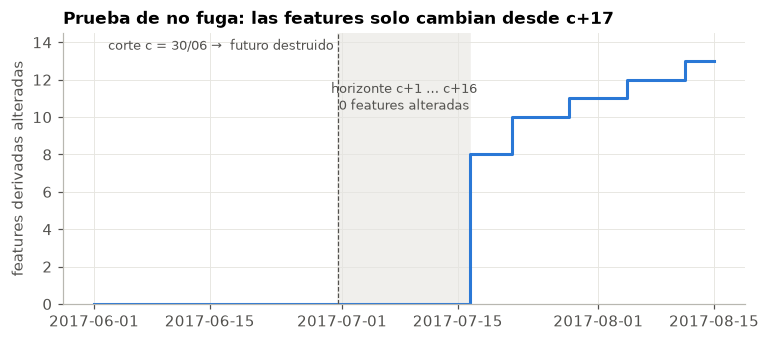

In [9]:
c = pd.Timestamp('2017-06-30')
serie = pruebas['2017-06-30'].loc['2017-06-01':'2017-08-15']
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.step(serie.index, serie.values, where='mid', color=AZUL, linewidth=2)
ax.axvspan(c + pd.Timedelta(days=0.5), c + pd.Timedelta(days=16.5), color=GRIS, zorder=0)
ax.axvline(c + pd.Timedelta(days=0.5), color=TINTA_2, linewidth=0.8, linestyle='--')
ax.text(c + pd.Timedelta(days=8.5), len(DERIVADAS) * 0.8, 'horizonte c+1 … c+16\n0 features alteradas',
        ha='center', fontsize=8.5, color=TINTA_2)
ax.text(c, len(DERIVADAS) + 0.6, 'corte c = 30/06 →  futuro destruido', ha='right', fontsize=8.5, color=TINTA_2)
ax.set_ylim(0, len(DERIVADAS) + 1.5)
ax.set_ylabel('features derivadas alteradas')
ax.set_title('Prueba de no fuga: las features solo cambian desde c+17')
fig.savefig(f'{FIGURAS}/features_no_fuga.png')
plt.show()

### 5.3 Columnas prohibidas

Ninguna columna de `EXCLUIDAS` (objetivo sin recortar, auditoría del PSet 2, variables del mismo
día) ni el propio objetivo llegan a la matriz que ve el modelo.

In [10]:
entradas = set(X_ent.columns)
usadas_por_preparacion = {c for _, _, cols in preparar.transformers_ if cols != 'drop' for c in cols}
prohibidas = set(EXCLUIDAS) | {OBJETIVO}
print('Columnas que usa la preparación:', len(usadas_por_preparacion))
print('Intersección con prohibidas:', usadas_por_preparacion & prohibidas or 'ninguna')
comprobar(4, not (entradas & prohibidas) and not (usadas_por_preparacion & prohibidas))

Columnas que usa la preparación: 28
Intersección con prohibidas: ninguna
Comprobación 4: OK


## 6. Ablación: ¿entra `ONPROMOTION`?

La promoción se planifica de antemano, así que en principio está disponible al predecir. Pero el
EDA (§5.3) encontró una **fuga parcial**. Los días sin venta que el PSet 2 reconstruyó como ceros
recibieron `ONPROMOTION = FALSE` por imputación, de modo que en este panel **una promoción nunca
coincide con venta cero**:

In [11]:
pd.crosstab([previo['IS_OBSERVED'].rename('fila observada')],
            [(previo[OBJETIVO] == 0).rename('venta cero'), previo['ONPROMOTION'].rename('promoción')])

venta cero       False          True 
promoción            0      1       0
fila observada                       
False                0      0  150176
True            361975  80986      37

Así, un modelo puede aprender "promoción = 0 → quizá fue un cero reconstruido". Esa regla no
describe la demanda: describe cómo se armó la tabla. En producción la promoción se conoce también
para los días en que no se vende, y la regla deja de valer.

**Diseño de la ablación.** El mismo modelo (`HistGradientBoostingRegressor` por defecto, sobre
`log1p`) se entrena dos veces, con y sin `ONPROMOTION`, hasta el 14/07 y se valida en 15/07–30/07.
El error se separa por segmentos usando la marca de auditoría `IS_OBSERVED` **solo para analizar**,
nunca como entrada.

In [12]:
def ablacion(con_promocion):
    extra = ['IS_OBSERVED'] + ([] if con_promocion else PROMOCION)
    X_ent, X_val, y_ent, y_val = dividir(datos, inicio_prueba='2017-07-15',
                                         con_promocion=con_promocion, columnas_extra=extra)
    modelo = Pipeline([
        ('preparar', preparacion(con_promocion)),
        ('modelo', TransformedTargetRegressor(HistGradientBoostingRegressor(random_state=42),
                                              func=np.log1p, inverse_func=np.expm1)),
    ])
    inicio = time.perf_counter()
    modelo.fit(X_ent, y_ent)
    p = modelo.predict(X_val)
    segundos = time.perf_counter() - inicio
    obs = X_val['IS_OBSERVED'].to_numpy().astype(bool)
    promo = X_val['ONPROMOTION'].to_numpy() == 1
    segmentos = {
        'total': np.ones_like(obs),
        'ventas observadas sin promoción': obs & ~promo,
        'ventas observadas con promoción': obs & promo,
        'ceros reconstruidos': ~obs,
    }
    fila = {n: rmsle(y_val[m], p[m]) for n, m in segmentos.items()}
    filas = {n: int(m.sum()) for n, m in segmentos.items()}
    return fila, filas, segundos


resultados = {}
for con in (False, True):
    fila, filas, segundos = ablacion(con)
    resultados['con ONPROMOTION' if con else 'sin ONPROMOTION'] = fila
    print(f"{'con' if con else 'sin'} promoción: {segundos:.0f} s")

tabla = pd.DataFrame(resultados)
tabla['filas'] = pd.Series(filas)
tabla['cambio_%'] = 100 * (tabla['con ONPROMOTION'] / tabla['sin ONPROMOTION'] - 1)
tabla

sin promoción: 22 s


con promoción: 22 s


,sin ONPROMOTION,con ONPROMOTION,filas,cambio_%
total,0.6456,0.6209,32000,-3.8329
ventas observadas sin promoción,0.5628,0.5819,19110,3.4026
ventas observadas con promoción,0.6795,0.5402,3753,-20.5085
ceros reconstruidos,0.7795,0.7224,9137,-7.3277


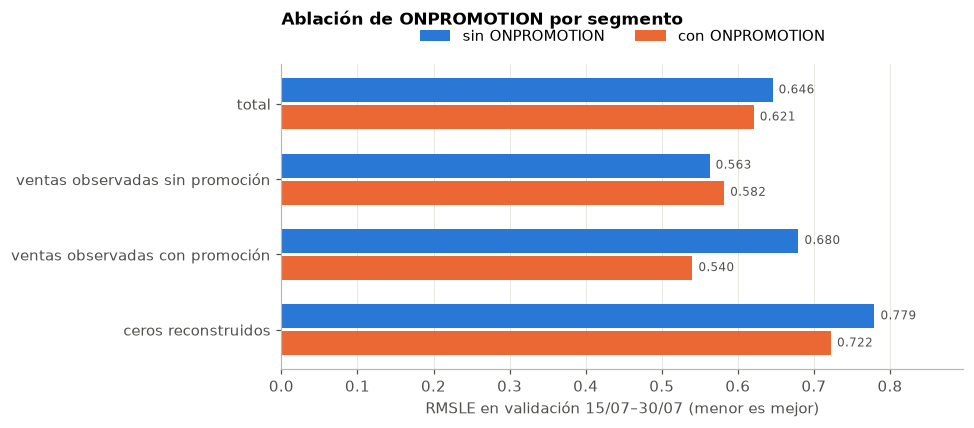

In [13]:
segmentos = list(tabla.index)[::-1]
y_pos = np.arange(len(segmentos))
alto = 0.36
fig, ax = plt.subplots(figsize=(8, 3.6))
for desplaza, columna, color in [(alto / 2, 'sin ONPROMOTION', AZUL), (-alto / 2, 'con ONPROMOTION', NARANJA)]:
    valores = tabla.loc[segmentos, columna]
    ax.barh(y_pos + desplaza, valores, height=alto - 0.04, color=color, label=columna)
    for y, v in zip(y_pos + desplaza, valores):
        ax.text(v + 0.008, y, f'{v:.3f}', va='center', fontsize=8, color=TINTA_2)
ax.set_yticks(y_pos, segmentos)
ax.set_xlabel('RMSLE en validación 15/07–30/07 (menor es mejor)')
ax.set_xlim(0, tabla[['sin ONPROMOTION', 'con ONPROMOTION']].to_numpy().max() * 1.15)
ax.set_title('Ablación de ONPROMOTION por segmento', pad=26)
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=2, frameon=False)
ax.grid(axis='y', visible=False)
fig.savefig(f'{FIGURAS}/features_ablacion_promocion.png')
plt.show()

In [14]:
cambio = tabla['cambio_%']
comprobar(5, cambio['ventas observadas sin promoción'] > 0 and cambio['ceros reconstruidos'] < 0)

Comprobación 5: OK


**Decisión: `ONPROMOTION` queda fuera del modelo principal.** La tabla muestra tres efectos
mezclados:

1. **Señal real.** En ventas observadas con promoción, el error baja mucho: la promoción sí mueve
   la demanda.
2. **Artefacto.** En los ceros reconstruidos, el error también baja, pero ahí la promoción vale 0
   por imputación y no por planificación. El modelo aprende la regla "sin promoción → posible cero".
3. **Daño en el caso más frecuente.** Esa misma regla **empeora** las ventas observadas sin
   promoción, que son la mayoría de los días con venta.

La mejora total no se trasladaría a producción. Allí la promoción se conoce también en los días sin
venta, y existirán combinaciones (promoción + venta cero) que el modelo nunca vio. Aceptarla
inflaría la métrica de validación y de prueba con una señal que solo existe en esta tabla. Se deja
como **limitación y trabajo futuro** del memo: con las promociones planificadas de todos los días
(el archivo de prueba de Kaggle las trae), la feature podría usarse sin fuga.

## 7. Resumen

| Bloque | Columnas | Preparación |
|---|---|---|
| `numericas` | 13 derivadas (rezagos 16–42, medias y dispersión desde t−16, intermitencia, nivel, transacciones rezagadas) + día del mes + n.º de eventos | mediana + indicador de faltante, estandarizar |
| `ya_listas` | 8 marcas de calendario y feriados (0/1) | sin cambios |
| `categoricas` | día de la semana, familia, clase, tipo y clúster de tienda | moda, one-hot con infrecuentes |

Comprobaciones superadas:

1. Recálculo manual de rezagos y medias.
2. Las features de la prueba no dependen de sus ventas.
3. Control positivo: las features sí cambian desde *c+17*.
4. Ninguna columna prohibida entra al modelo.
5. Decisión sobre la promoción respaldada por la ablación.

**Siguiente (notebook 03):** validación temporal, líneas base y candidatos registrados en MLflow.